# Burke GDP response along the pathway: year-matched, compounded

The matched-GWL comparison (`ramip_gdp_burke.ipynb`) asks what a 2 °C world costs under each pathway, which removes the main
economic channel of aerosol cleanup: more global warming, sooner. This notebook follows the actual pathways year by year from
2015 and compounds Burke's growth response, as his own projections do:

- country temperature in year *y* = observed 1980–2010 mean + his CMIP5 country/global ratio × (1.20 − 0.65) K, the warming
  from his baseline period to the first RAMIP decade, + the model's anomaly of that year about its own 2015–2024 parent mean;
- Δg(y) = g(T_arm,y) − g(T_parent,y), same member, pooled no-lag specification, 30 °C cap;
- the GDP-per-capita ratio of the arm to the parent, Π(1 + Δg(y)) − 1, by 2050 (every model reaches 2050; CanESM5-1 ends
  2051) and at each run's end (2059–2100 elsewhere);
- its split into the part a uniform warming pattern would give (parent + his country/global ratio × the arm-minus-parent
  GMST of that year) and the remainder, the regional pattern of the cleanup;
- Burke's coefficient uncertainty from the 1000 bootstrap draws, each compounded exactly.

Only arm-to-arm differences are meaningful; growth is compounded relative to the parent pathway, not projected in levels.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/code')
sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/path_independence')
sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/path_independence/gdp')
from funcs_support import get_params
import ks_tools as kt
import burke
from country_tas import ARMS, PARENT, POP_DIR

dir_list = get_params()
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 230)

GDP_DIR = dir_list['aux'] + 'diagnostics/gdp/'
DL_DIR  = dir_list['aux'] + 'data_layer/'
GWL_DIR = dir_list['aux'] + 'diagnostics/ramip_gwl/'
PRODUCT = dir_list['aux'] + 'gwl_timeseries.zarr'
out_dir = dir_list['aux'] + '../figures/e8_gdp_burke/'
os.makedirs(out_dir, exist_ok=True)
GWL, WIN, NDRAWS = 2.0, kt.WIN, 1000
LABEL = {'glob': '126aer (global cleanup)', 'eas': 'EAS126aer', 'sas': 'SAS126aer', 'afr': 'AFR126aer', 'nae': 'NAE126aer',
         'asia': 'ASIA126aer', 'safca': 'SAF126ca', 'sasca': 'SAS126ca'}
SPECS = {'pooled': 'pooled, no lags (main)', 'lag5': 'pooled, 5 lags, cumulative', 'richpoor': 'rich / poor, no lags'}

# Burke's three regressions, re-estimated from his panel with his 1000-draw country bootstrap (cached)
COEF = {}
for spec in SPECS:
    fn = GDP_DIR + f'burke_coef_{spec}.csv'
    if os.path.exists(fn):
        COEF[spec] = pd.read_csv(fn)
    else:
        COEF[spec] = burke.fit(spec, NDRAWS)
        COEF[spec].to_csv(fn, index=False)
    b1, b2, p1, p2 = burke.coefs(COEF[spec], spec)
    ok = b2[1:] < 0
    print(f'{SPECS[spec]:30s} temp {b1[0]:+.6f}  temp2 {b2[0]:+.7f}  optimum {-b1[0] / (2 * b2[0]):5.1f} C, '
          f'bootstrap 5-95 %: {np.percentile(-b1[1:][ok] / (2 * b2[1:][ok]), 5):.1f}-{np.percentile(-b1[1:][ok] / (2 * b2[1:][ok]), 95):.1f} C'
          + (f'; poor countries: temp {p1[0]:+.6f} temp2 {p2[0]:+.7f}' if p1 is not None else ''))
b1, b2 = burke.coefs(COEF['pooled'], 'pooled')[:2]
assert (round(b1[0], 4), round(b2[0], 4)) == (kt.B1, kt.B2), 'the pooled point estimate must round to the published pair'

# countries (the cache's order), World Bank economy, Burke's observational baselines
cty = pd.read_csv(GDP_DIR + 'countries.csv')
wb = pd.read_csv(DL_DIR + 'worldbank_gdp_pop.csv', index_col=0)
ALIAS = {'KOS': 'XKX', 'SDS': 'SSD', 'PSX': 'PSE'}                              # Natural Earth code -> World Bank code
econ = cty.set_index('iso3').join(wb[['gdp_pc', 'gdp', 'pop_wb']].rename(index={v: k for k, v in ALIAS.items()}))
econ['poor'] = econ.gdp_pc <= econ.gdp_pc.median()                             # Burke's projection rule: at or below the median GDP per capita
econ = econ.join(burke.baseline()[['meantemp', 'tconv']])
C, n_c = econ.index.values, len(econ)
has = (econ.meantemp.notna() & econ.gdp.notna()).values                        # countries that carry money: a baseline and a GDP
print(f'{n_c} countries; {int(econ.gdp.notna().sum())} with World Bank GDP; {int(econ.meantemp.notna().sum())} with a Burke baseline; '
      f'{int(has.sum())} with both ({100 * econ.gdp[has].sum() / econ.gdp.sum():.1f} % of world GDP)')
gdp_w = np.where(has, econ.gdp.fillna(0).values, 0.0)                          # US$ (constant 2015), 2019
pop_w = np.where(has, econ.pop_wb.fillna(0).values, 0.0); pop_w = pop_w / pop_w.sum()

# the country-temperature cache (gdp/country_tas.py)
TAS = {}
for mod in PARENT:
    fn = GDP_DIR + f'country_tas_{mod}.nc'
    if os.path.exists(fn):
        TAS[mod] = xr.open_dataset(fn).load()
        assert list(TAS[mod].country.values) == list(C)
print('models with the cache:', list(TAS))


def series(mod, exp, run, y0, y1):
    """annual country temperature (country, year) of one run over y0..y1, or None if those years are not all there"""
    ds = TAS[mod]
    i = np.flatnonzero((ds.exp.values == exp) & (ds.run.values == run))
    if len(i) != 1:
        return None
    v = ds.tas.isel(series=i[0]).sel(year=slice(y0, y1)).values.T
    return v if v.shape[1] == y1 - y0 + 1 and np.isfinite(v).all() else None

pooled, no lags (main)         temp +0.012718  temp2 -0.0004871  optimum  13.1 C, bootstrap 5-95 %: 9.9-16.7 C
pooled, 5 lags, cumulative     temp -0.003709  temp2 -0.0000967  optimum -19.2 C, bootstrap 5-95 %: -119.7-15.9 C
rich / poor, no lags           temp +0.008894  temp2 -0.0003154  optimum  14.1 C, bootstrap 5-95 %: 8.3-32.5 C; poor countries: temp +0.025433 temp2 -0.0007720


228 countries; 205 with World Bank GDP; 166 with a Burke baseline; 165 with both (98.9 % of world GDP)
models with the cache: ['CanESM5-1', 'CNRM-ESM2-1', 'EC-Earth3-AerChem', 'GISS-E2-1-G', 'MIROC6', 'MRI-ESM2-0', 'NorESM2-LM', 'UKESM1-0-LL', 'CESM2']


In [2]:
Y0, YEND, Y2050 = 2015, 2100, 2050
_gmst = xr.open_zarr(PRODUCT, group='gmst')
rows, TPf, TAf, DGM = [], [], [], []
for arm, exp in ARMS.items():
    for mod in TAS:
        ds = TAS[mod]
        pr = {r: i for i, (e, r) in enumerate(zip(ds.exp.values, ds.run.values)) if e == PARENT[mod]}
        ar = {r: i for i, (e, r) in enumerate(zip(ds.exp.values, ds.run.values)) if e == exp}
        ids_p = list(_gmst.run_id.sel(model=mod, exp=PARENT[mod]).values); ids_a = list(_gmst.run_id.sel(model=mod, exp=exp).values)
        for run in sorted(set(pr) & set(ar)):
            tp, ta = ds.tas.isel(series=pr[run]).values.T, ds.tas.isel(series=ar[run]).values.T
            if any(np.isnan(t[0, :np.flatnonzero(np.isfinite(t[0]))[-1] + 1]).any() for t in (tp, ta)):
                print(f'  {arm} {mod} {run}: a year is missing inside the run, skipped'); continue
            gp = _gmst.gmst_anom.sel(model=mod, exp=PARENT[mod]).isel(member=ids_p.index(run)).sel(year=slice(Y0, YEND)).values
            ga = _gmst.gmst_anom.sel(model=mod, exp=exp).isel(member=ids_a.index(run)).sel(year=slice(Y0, YEND)).values
            rows.append((arm, mod, run)); TPf.append(tp); TAf.append(ta)
            DGM.append(ga - gp)
pairs = pd.DataFrame(rows, columns=['arm', 'model', 'run'])
TPf, TAf, DGM = np.stack(TPf), np.stack(TAf), np.stack(DGM)                      # (pair, country, year) and (pair, year); NaN past a run's end
DGM[np.isnan(TPf[:, 0, :]) | np.isnan(TAf[:, 0, :])] = np.nan                   # the product's last, partial year is not in the cache
years = np.arange(Y0, YEND + 1)
assert TPf.shape[-1] == len(years) == DGM.shape[-1]
print('pairs per arm:', pairs.groupby('arm').size().to_dict())

b1, b2 = burke.coefs(COEF['pooled'], 'pooled')[:2]
L = (econ.meantemp + econ.tconv * (burke.GMST_2015_2024 - burke.GMST_1980_2010)).values[None, :, None]
ref = TPf[:, :, :10].mean(-1, keepdims=True)                                     # the parent's 2015-2024 mean
Tp, Ta = L + TPf - ref, L + TAf - ref
Tu = Tp + econ.tconv.values[None, :, None] * DGM[:, None, :]                     # uniform-pattern counterfactual of the arm


def dg_year(T0, T1):
    """Burke's growth-rate difference every year (pair, country, year); NaN where either side has ended"""
    T0, T1 = np.minimum(T0, burke.CAP), np.minimum(T1, burke.CAP)
    return b1[0] * (T1 - T0) + b2[0] * (T1 ** 2 - T0 ** 2)


def compound(dg):
    """GDP-per-capita ratio to the parent minus one, by year; NaN where the pathway has ended"""
    c = np.cumprod(1 + np.nan_to_num(dg), axis=-1) - 1
    return np.where(np.isnan(dg), np.nan, c)


dg_y, dg_u = dg_year(Tp, Ta), dg_year(Tp, Tu)
cum, cum_u = compound(dg_y), compound(dg_u)
ok = np.tile(has, (len(pairs), 1))[:, :, None]
w_gdp = np.where(has, gdp_w, 0) / gdp_w.sum()
world = np.einsum('pcy,c->py', np.nan_to_num(cum), w_gdp); world[np.isnan(cum[:, has].mean(1))] = np.nan      # GDP-weighted, i.e. share of world GDP
world_u = np.einsum('pcy,c->py', np.nan_to_num(cum_u), w_gdp); world_u[np.isnan(world)] = np.nan
dgw = np.einsum('pcy,c->py', np.nan_to_num(dg_y), w_gdp); dgw[np.isnan(world)] = np.nan

i50 = Y2050 - Y0
last = np.array([np.max(np.flatnonzero(np.isfinite(world[p]))) for p in range(len(pairs))])
pairs['end_year'] = years[last]
pairs['gmst_lead_2050'] = DGM[:, i50]
pairs['gmst_lead_mean_to_2050'] = DGM[:, :i50 + 1].mean(1)
pairs['cum_2050_pct'] = 100 * world[:, i50]
pairs['cum_2050_uniform_pct'] = 100 * world_u[:, i50]
pairs['cum_end_pct'] = 100 * world[np.arange(len(pairs)), last]
pairs['dg_popw_2050'] = np.einsum('pc,c->p', np.nan_to_num(dg_y[:, :, i50]), pop_w)
bym = pairs.groupby(['arm', 'model']).agg(pairs=('run', 'size'), end_year=('end_year', 'min'), gmst_lead_2050=('gmst_lead_2050', 'mean'),
                                          cum_2050_pct=('cum_2050_pct', 'mean'), cum_2050_uniform_pct=('cum_2050_uniform_pct', 'mean'),
                                          cum_end_pct=('cum_end_pct', 'mean')).reset_index()
summary = bym.groupby('arm').agg(models=('model', 'nunique'), pairs=('pairs', 'sum'), gmst_lead_2050=('gmst_lead_2050', 'mean'),
                                 cum_2050_pct=('cum_2050_pct', 'mean'), cum_2050_sd=('cum_2050_pct', 'std'),
                                 cum_2050_uniform_pct=('cum_2050_uniform_pct', 'mean'), cum_end_pct=('cum_end_pct', 'mean'),
                                 models_negative=('cum_2050_pct', lambda s: int((s < 0).sum())))
# coefficient uncertainty at 2050: every draw compounded exactly, in chunks of draws
Ay = (np.minimum(Ta, burke.CAP) - np.minimum(Tp, burke.CAP))[:, :, :i50 + 1]
By = (np.minimum(Ta, burke.CAP) ** 2 - np.minimum(Tp, burke.CAP) ** 2)[:, :, :i50 + 1]
wd = np.empty((len(b1), len(pairs)))                                             # (draw, pair) world share
for d0 in range(0, len(b1), 50):
    sl = slice(d0, d0 + 50)
    x = b1[sl, None, None, None] * Ay[None] + b2[sl, None, None, None] * By[None]
    wd[sl] = np.einsum('dpc,c->dp', np.nan_to_num(np.cumprod(1 + x, axis=-1)[..., -1] - 1), w_gdp)
assert np.allclose(wd[0], world[:, i50], atol=1e-9)
mmw = pd.DataFrame(wd.T).groupby([pairs.arm, pairs.model]).mean().groupby('arm').mean()     # model mean per draw
summary['coef_p05_2050_pct'] = 100 * mmw.iloc[:, 1:].quantile(0.05, axis=1)
summary['coef_p95_2050_pct'] = 100 * mmw.iloc[:, 1:].quantile(0.95, axis=1)
ARM_ORDER = ['glob', 'eas', 'sas', 'afr', 'nae', 'asia', 'safca', 'sasca']
summary = summary.loc[[a for a in ARM_ORDER if a in summary.index]]
summary.to_csv(GDP_DIR + 'pathway_summary.csv'); bym.to_csv(GDP_DIR + 'pathway_by_model.csv', index=False)
print('GDP per capita relative to the parent pathway, world (GDP-weighted), % by 2050 and at each run\'s end; '
      'uniform = the part a uniform warming pattern would give; gmst_lead = arm minus parent GMST in 2050 (K):')
print(summary.round(3).to_string())

# per country at 2050, global cleanup
cc = pd.DataFrame({'iso3': C})
for arm in ARMS:
    M = np.stack([np.nanmean(cum[idx, :, i50], 0) for (a, m), idx in pairs.groupby(['arm', 'model']).indices.items() if a == arm])
    cc[f'cum_2050_pct_{arm}'] = 100 * M.mean(0); cc[f'models_negative_{arm}'] = (M < 0).sum(0)
cc = cc.join(econ[['name', 'gdp', 'gdp_pc']], on='iso3')
cc.loc[~has, [c for c in cc.columns if c.startswith('cum_')]] = np.nan
cc.to_csv(GDP_DIR + 'pathway_country_2050.csv', index=False)
g = cc.dropna(subset=['cum_2050_pct_glob'])
print('\nglobal cleanup, GDP per capita relative to ssp370 by 2050, the 12 largest economies:')
print(g.reindex(g.gdp.sort_values(ascending=False).index).head(12)[['name', 'cum_2050_pct_glob', 'models_negative_glob']].round(2).to_string(index=False))

  eas UKESM1-0-LL r4i1p1f2: a year is missing inside the run, skipped


  afr CanESM5-1 r1i1p1f1: a year is missing inside the run, skipped


pairs per arm: {'afr': 82, 'asia': 26, 'eas': 82, 'glob': 83, 'nae': 82, 'safca': 20, 'sas': 82, 'sasca': 21}


GDP per capita relative to the parent pathway, world (GDP-weighted), % by 2050 and at each run's end; uniform = the part a uniform warming pattern would give; gmst_lead = arm minus parent GMST in 2050 (K):
       models  pairs  gmst_lead_2050  cum_2050_pct  cum_2050_sd  cum_2050_uniform_pct  cum_end_pct  models_negative  coef_p05_2050_pct  coef_p95_2050_pct
arm                                                                                                                                                      
glob        9     83           0.379        -3.446        1.578                -2.547       -7.541                9             -7.517              1.296
eas         9     82           0.105        -0.988        0.596                -0.616       -2.005                9             -2.170              0.333
sas         9     82           0.032        -0.531        0.172                -0.208       -1.298                9             -0.900             -0.138
afr         9     82    

/tmp/ipykernel_1634194/550474227.py:90: RuntimeWarning: Mean of empty slice
  M = np.stack([np.nanmean(cum[idx, :, i50], 0) for (a, m), idx in pairs.groupby(['arm', 'model']).indices.items() if a == arm])


/tmp/ipykernel_1634194/3753295869.py:7: RuntimeWarning: Mean of empty slice
  ms = np.stack([np.nanmean(x, 0) for (a, m), idx in gi.items() if a == arm for x in [dgw[idx]]])
/tmp/ipykernel_1634194/3753295869.py:9: RuntimeWarning: Mean of empty slice
  ms = np.stack([np.nanmean(x, 0) for (a, m), idx in gi.items() if a == arm for x in [world[idx]]])
/tmp/ipykernel_1634194/3753295869.py:13: RuntimeWarning: Mean of empty slice
  mu = np.stack([np.nanmean(x, 0) for (a, m), idx in gi.items() if a == arm for x in [world_u[idx]]])
/tmp/ipykernel_1634194/3753295869.py:15: RuntimeWarning: Mean of empty slice
  ms = np.stack([np.nanmean(x, 0) for (a, m), idx in gi.items() if a == arm for x in [DGM[idx]]])
/tmp/ipykernel_1634194/3753295869.py:19: RuntimeWarning: Mean of empty slice
  axs[2].plot(years, np.nanmean(DGM[idx], 0), lw=0.7, color='0.5')


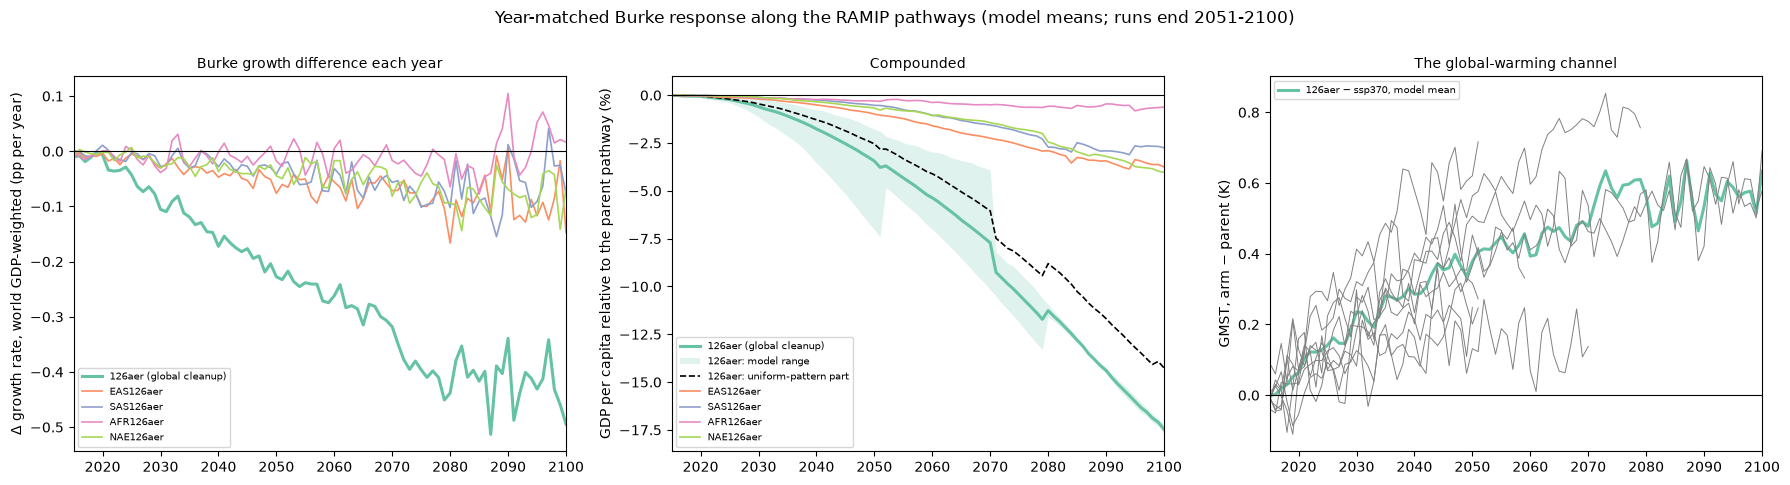

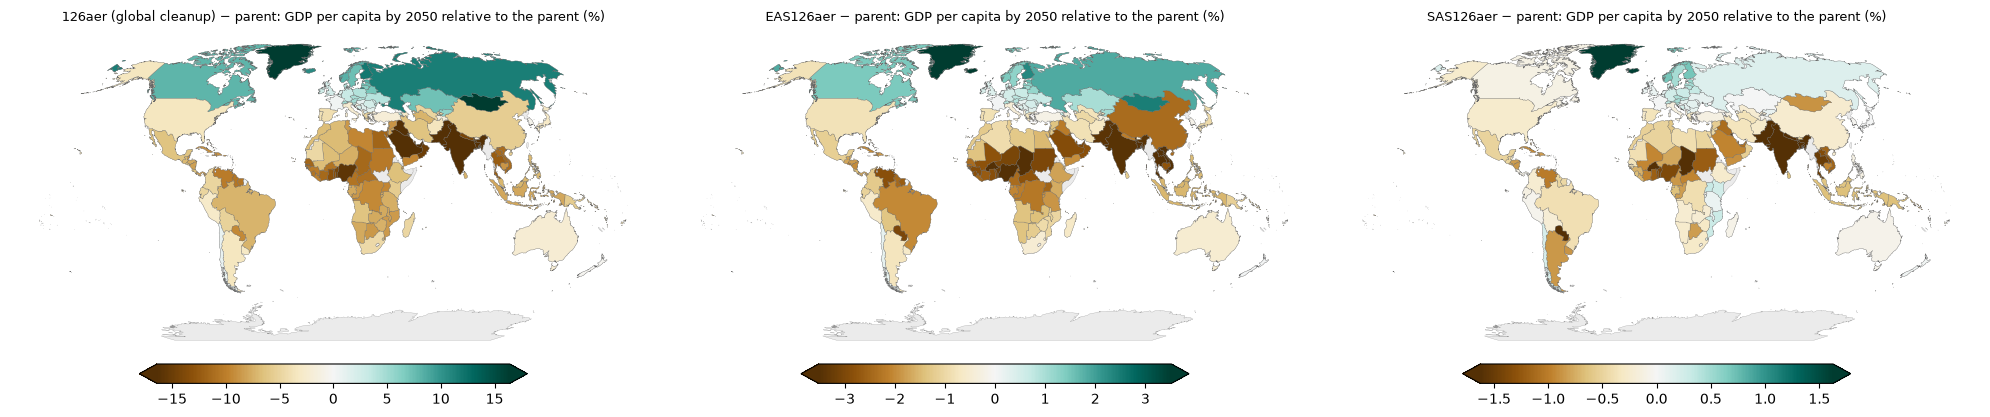

figures in /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e8_gdp_burke/


In [3]:
import geopandas as gpd
ne = gpd.read_file('zip://' + POP_DIR + 'ne_50m_admin_0_countries.zip').dissolve(by='ADM0_A3', aggfunc='first').reset_index()
world_geo = ne[['ADM0_A3', 'geometry']].rename(columns={'ADM0_A3': 'iso3'}).to_crs('ESRI:54030')
gi = pairs.groupby(['arm', 'model']).indices
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
for arm in ARM_ORDER[:5]:
    ms = np.stack([np.nanmean(x, 0) for (a, m), idx in gi.items() if a == arm for x in [dgw[idx]]])
    axs[0].plot(years, 100 * np.nanmean(ms, 0), lw=2.2 if arm == 'glob' else 1.2, label=LABEL[arm], color=plt.cm.Set2(ARM_ORDER.index(arm)))
    ms = np.stack([np.nanmean(x, 0) for (a, m), idx in gi.items() if a == arm for x in [world[idx]]])
    axs[1].plot(years, 100 * np.nanmean(ms, 0), lw=2.2 if arm == 'glob' else 1.2, label=LABEL[arm], color=plt.cm.Set2(ARM_ORDER.index(arm)))
    if arm == 'glob':
        axs[1].fill_between(years, 100 * np.nanmin(ms, 0), 100 * np.nanmax(ms, 0), color=plt.cm.Set2(0), alpha=0.2, lw=0, label='126aer: model range')
        mu = np.stack([np.nanmean(x, 0) for (a, m), idx in gi.items() if a == arm for x in [world_u[idx]]])
        axs[1].plot(years, 100 * np.nanmean(mu, 0), lw=1.2, ls='--', color='k', label='126aer: uniform-pattern part')
        ms = np.stack([np.nanmean(x, 0) for (a, m), idx in gi.items() if a == arm for x in [DGM[idx]]])
        axs[2].plot(years, np.nanmean(ms, 0), lw=2.2, color=plt.cm.Set2(0), label='126aer − ssp370, model mean')
        for (a, m), idx in gi.items():
            if a == arm:
                axs[2].plot(years, np.nanmean(DGM[idx], 0), lw=0.7, color='0.5')
axs[0].axhline(0, color='k', lw=0.8); axs[0].set_ylabel('Δ growth rate, world GDP-weighted (pp per year)'); axs[0].set_title('Burke growth difference each year', fontsize=10)
axs[1].axhline(0, color='k', lw=0.8); axs[1].set_ylabel('GDP per capita relative to the parent pathway (%)'); axs[1].set_title('Compounded', fontsize=10)
axs[2].axhline(0, color='k', lw=0.8); axs[2].set_ylabel('GMST, arm − parent (K)'); axs[2].set_title('The global-warming channel', fontsize=10)
for ax in axs:
    ax.set_xlim(Y0, YEND); ax.legend(fontsize=7)
fig.suptitle('Year-matched Burke response along the RAMIP pathways (model means; runs end 2051-2100)', y=1.0)
fig.tight_layout(); fig.savefig(out_dir + 'pathway_world.png', dpi=150, bbox_inches='tight'); plt.show()

d = world_geo.join(cc.set_index('iso3')[['cum_2050_pct_glob', 'cum_2050_pct_eas', 'cum_2050_pct_sas']], on='iso3')
fig, axs = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, arm in zip(axs, ['glob', 'eas', 'sas']):
    colname = f'cum_2050_pct_{arm}'
    lim = float(np.nanpercentile(d[colname].abs(), 95))
    world_geo.plot(ax=ax, color='0.92', edgecolor='0.6', linewidth=0.2)
    d.dropna(subset=[colname]).plot(ax=ax, column=colname, cmap='BrBG', vmin=-lim, vmax=lim, edgecolor='0.4', linewidth=0.2, legend=True,
                                    legend_kwds={'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.02})
    ax.set_title(f'{LABEL[arm]} − parent: GDP per capita by 2050 relative to the parent (%)', fontsize=9); ax.set_axis_off()
fig.tight_layout(); fig.savefig(out_dir + 'pathway_map_2050.png', dpi=140, bbox_inches='tight'); plt.show()
print('figures in', out_dir)

## Reading the results

**Along the pathway the cleanup's extra warming dominates.** With the same member on both sides, ssp370-126aer is 0.38 K warmer
than ssp370 by 2050 (model mean), and Burke's growth response compounds to −3.4 ± 1.6 % of GDP per capita by 2050 relative to
the ssp370 pathway (9 of 9 models negative; Burke coefficient 5–95 %: −7.5 to +1.3 %), and −7.5 % at the end of the runs
(2051–2100, a mix of horizons). A uniform warming pattern with the same GMST difference would give −2.5 % by 2050: three quarters
of the loss is the global-warming channel, the rest is the regional pattern, the same pattern that produces the matched-GWL result.

**Regional arms.** EAS −1.0 ± 0.6 %, NAE −0.7 ± 0.6 %, SAS −0.5 ± 0.2 %, AFR −0.3 ± 0.2 % by 2050, every model negative. NAE
now costs: its extra global warming (0.09 K; uniform part −0.84 %) outweighs the slightly favourable pattern (+0.16 %) that gave it
no loss at a fixed level. SAS and AFR are robust to the coefficients (90 % range entirely negative); EAS and NAE are not.

**Countries.** India −19.6 % by 2050 (every model), Brazil −7.3, China −5.5, the United States −3.4, Japan −3.1; Canada +8.0,
Germany +3.1, the United Kingdom +2.2. These are Burke's growth effects compounded over 35 years at a few tenths of a degree of
extra warming, large for hot countries by construction of the framework; read them as its implication, not as a projection.

**Caveats.** Growth is compounded relative to the parent pathway, not projected in levels, so population and baseline growth drop
out. Temperature levels are observation-anchored (UDel 1980–2010 plus 0.55 K × Burke's country/global ratio for the warming to
2015–2024) and the models supply the anomalies about their own 2015–2024 parent mean; the 30 °C cap holds the response flat above
that; the pooled no-lag specification only. Two pairs with a year missing inside the run are skipped (CanESM5-1 AFR126aer r1,
2040; UKESM1-0-LL EAS126aer r4). Horizons differ across models (CanESM5-1 ends in 2051, MIROC6 in 2100); the 2050 number is the
comparable one. Figures: `pathway_world.png`, `pathway_map_2050.png`.